# Partie 1 - AdaBoost sur MNIST

On distingue deux classes binaires : les chiffres de 0 a 4 (classe 0) et ceux de 5 a 9 (classe 1). On compare des decision stumps, des perceptrons et des arbres de decision de profondeurs differentes, puis on observe les matrices de confusion a plusieurs etapes du boosting.

Les images restent representees par leurs 784 pixels : aucune reduction de dimension par ACP n'est appliquee.

In [ ]:
from pathlib import Path

import inspect
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,confusion_matrix
from sklearn.tree import DecisionTreeClassifier

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## Chargement et preparation des donnees

MNIST fournit 60 000 exemples d'entrainement et 10 000 exemples de test. Les intensites des pixels sont ramenees dans [0, 1].

In [ ]:
from sklearn.datasets import fetch_openml

directory = "data"
#telecharger jeu de donnée MNIST
mnist = fetch_openml('mnist_784', version=1, data_home=directory, as_frame=False, parser='liac-arff')


In [5]:
X_train = mnist.data[:60000]
y_train = mnist.target[:60000]

X_test = mnist.data[60000:70000]
y_test = mnist.target[60000:70000]

print('Train :',X_train.shape, y_train.shape)
print('Test :', X_test.shape, y_test.shape)

Train : (60000, 784) (60000,)
Test : (10000, 784) (10000,)


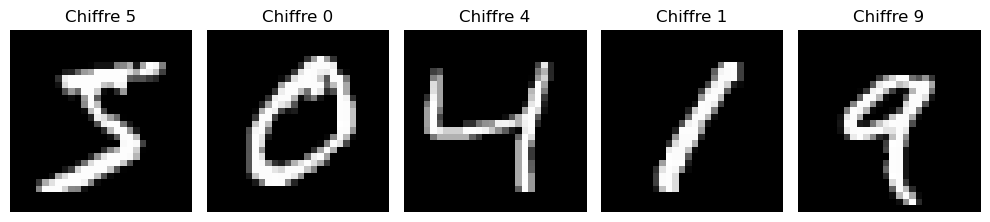

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(10, 2.5))
for ax, image, label in zip(axes, X_train[:5], y_train[:5]):
    ax.imshow(image.reshape(28, 28), cmap='gray')
    ax.set_title(f'Chiffre {label}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Construction des deux classes

Le label binaire 0 correspond aux chiffres 0, 1, 2, 3 et 4 ; le label 1 correspond aux chiffres 5, 6, 7, 8 et 9.

In [11]:
noms_classes = ['Chiffres 0-4', 'Chiffres 5-9']

X_train_bin, X_test_bin = X_train, X_test
y_train_bin = (y_train.astype(int) >= 5).astype(np.int8)
y_test_bin = (y_test.astype(int) >= 5).astype(np.int8)

print('Effectifs train :', dict(zip(*np.unique(y_train_bin, return_counts=True))))
print('Effectifs test  :', dict(zip(*np.unique(y_test_bin, return_counts=True))))
print('Dimensions utilisees :', X_train_bin.shape, X_test_bin.shape)

Effectifs train : {0: 30596, 1: 29404}
Effectifs test  : {0: 5139, 1: 4861}
Dimensions utilisees : (60000, 784) (10000, 784)


## Algorithme AdaBoost binaire

On utilise directement `AdaBoostClassifier` de scikit-learn. Le mode SAMME est selectionne sur les versions qui proposent ce parametre, car le perceptron ne fournit pas de probabilites (`predict_proba`).

In [15]:
def creer_adaboost(classifieur, nb_etapes):
    parametres = {
        'estimator': classifieur,
        'n_estimators': nb_etapes,
        'learning_rate': 1.0,
        'random_state': RANDOM_SEED,
    }
    if 'algorithm' in inspect.signature(AdaBoostClassifier).parameters:
        parametres['algorithm'] = 'SAMME'
    return AdaBoostClassifier(**parametres)

## Experiences et matrices de confusion

On compare un stump (arbre de profondeur 1), un perceptron et trois profondeurs d'arbres. Les matrices sont calculees aux etapes demandees ; si un modele converge avant, le nombre effectif d'etapes est indique.

In [16]:
NB_ETAPES = 50
ETAPES_A_EVALUER = [1, 10, 20, 30, 40, 50]

configurations = {
    'Stump (profondeur 1)': DecisionTreeClassifier(
        max_depth=1, random_state=RANDOM_SEED
    ),
    'Perceptron': Perceptron(
        max_iter=5, tol=None, random_state=RANDOM_SEED
    ),
    'Arbre (profondeur 3)': DecisionTreeClassifier(
        max_depth=3, random_state=RANDOM_SEED
    ),
    'Arbre (profondeur 5)': DecisionTreeClassifier(
        max_depth=5, random_state=RANDOM_SEED
    ),
    'Arbre (profondeur 10)': DecisionTreeClassifier(
        max_depth=10, random_state=RANDOM_SEED
    ),
}

resultats = []
matrices = {}

for nom, classifieur in configurations.items():
    print(f'Entrainement : {nom}')
    modele = creer_adaboost(classifieur, NB_ETAPES)
    modele.fit(X_train_bin, y_train_bin)
    if not modele.estimators_:
        raise RuntimeError(f'Aucun estimateur AdaBoost appris pour {nom}.')
    matrices[nom] = {}

    etapes_effectives = sorted(
        {min(n, len(modele.estimators_)) for n in ETAPES_A_EVALUER}
    )
    for n, y_pred in enumerate(modele.staged_predict(X_test_bin), start=1):
        if n not in etapes_effectives:
            continue
        cm = confusion_matrix(y_test_bin, y_pred, labels=[0, 1])
        matrices[nom][n] = cm
        resultats.append({
            'Classifieur faible': nom,
            'Etapes': n,
            'Accuracy': accuracy_score(y_test_bin, y_pred),
            'Balanced accuracy': balanced_accuracy_score(y_test_bin, y_pred),
            'Matrice de confusion': cm.tolist(),
        })
        print(f'{nom} - {n} etapes - matrice :\n{cm}')

table_resultats = pd.DataFrame(resultats)
table_resultats

Entrainement : Stump (profondeur 1)
Stump (profondeur 1) - 1 etapes - matrice :
[[2990 2149]
 [ 857 4004]]
Stump (profondeur 1) - 10 etapes - matrice :
[[3705 1434]
 [ 895 3966]]
Stump (profondeur 1) - 20 etapes - matrice :
[[4051 1088]
 [ 932 3929]]
Stump (profondeur 1) - 30 etapes - matrice :
[[4066 1073]
 [ 953 3908]]
Stump (profondeur 1) - 40 etapes - matrice :
[[4147  992]
 [ 953 3908]]
Stump (profondeur 1) - 50 etapes - matrice :
[[4127 1012]
 [ 917 3944]]
Entrainement : Perceptron
Perceptron - 1 etapes - matrice :
[[4632  507]
 [1447 3414]]
Perceptron - 9 etapes - matrice :
[[4501  638]
 [1040 3821]]
Entrainement : Arbre (profondeur 3)
Arbre (profondeur 3) - 1 etapes - matrice :
[[3583 1556]
 [ 879 3982]]
Arbre (profondeur 3) - 10 etapes - matrice :
[[4314  825]
 [ 824 4037]]
Arbre (profondeur 3) - 20 etapes - matrice :
[[4509  630]
 [ 596 4265]]
Arbre (profondeur 3) - 30 etapes - matrice :
[[4578  561]
 [ 521 4340]]
Arbre (profondeur 3) - 40 etapes - matrice :
[[4715  424]
 [ 4

,Classifieur faible,Etapes,Accuracy,Balanced accuracy,Matrice de confusion
0,Stump (profondeur 1),1,0.6994,0.702762,"[[2990, 2149], [857, 4004]]"
1,Stump (profondeur 1),10,0.7671,0.768419,"[[3705, 1434], [895, 3966]]"
2,Stump (profondeur 1),20,0.7980,0.798278,"[[4051, 1088], [932, 3929]]"
3,Stump (profondeur 1),30,0.7974,0.797577,"[[4066, 1073], [953, 3908]]"
4,Stump (profondeur 1),40,0.8055,0.805458,"[[4147, 992], [953, 3908]]"
5,Stump (profondeur 1),50,0.8071,0.807215,"[[4127, 1012], [917, 3944]]"
6,Perceptron,1,0.8046,0.801834,"[[4632, 507], [1447, 3414]]"
7,Perceptron,9,0.8322,0.830952,"[[4501, 638], [1040, 3821]]"
8,Arbre (profondeur 3),1,0.7565,0.758195,"[[3583, 1556], [879, 3982]]"
9,Arbre (profondeur 3),10,0.8351,0.834975,"[[4314, 825], [824, 4037]]"


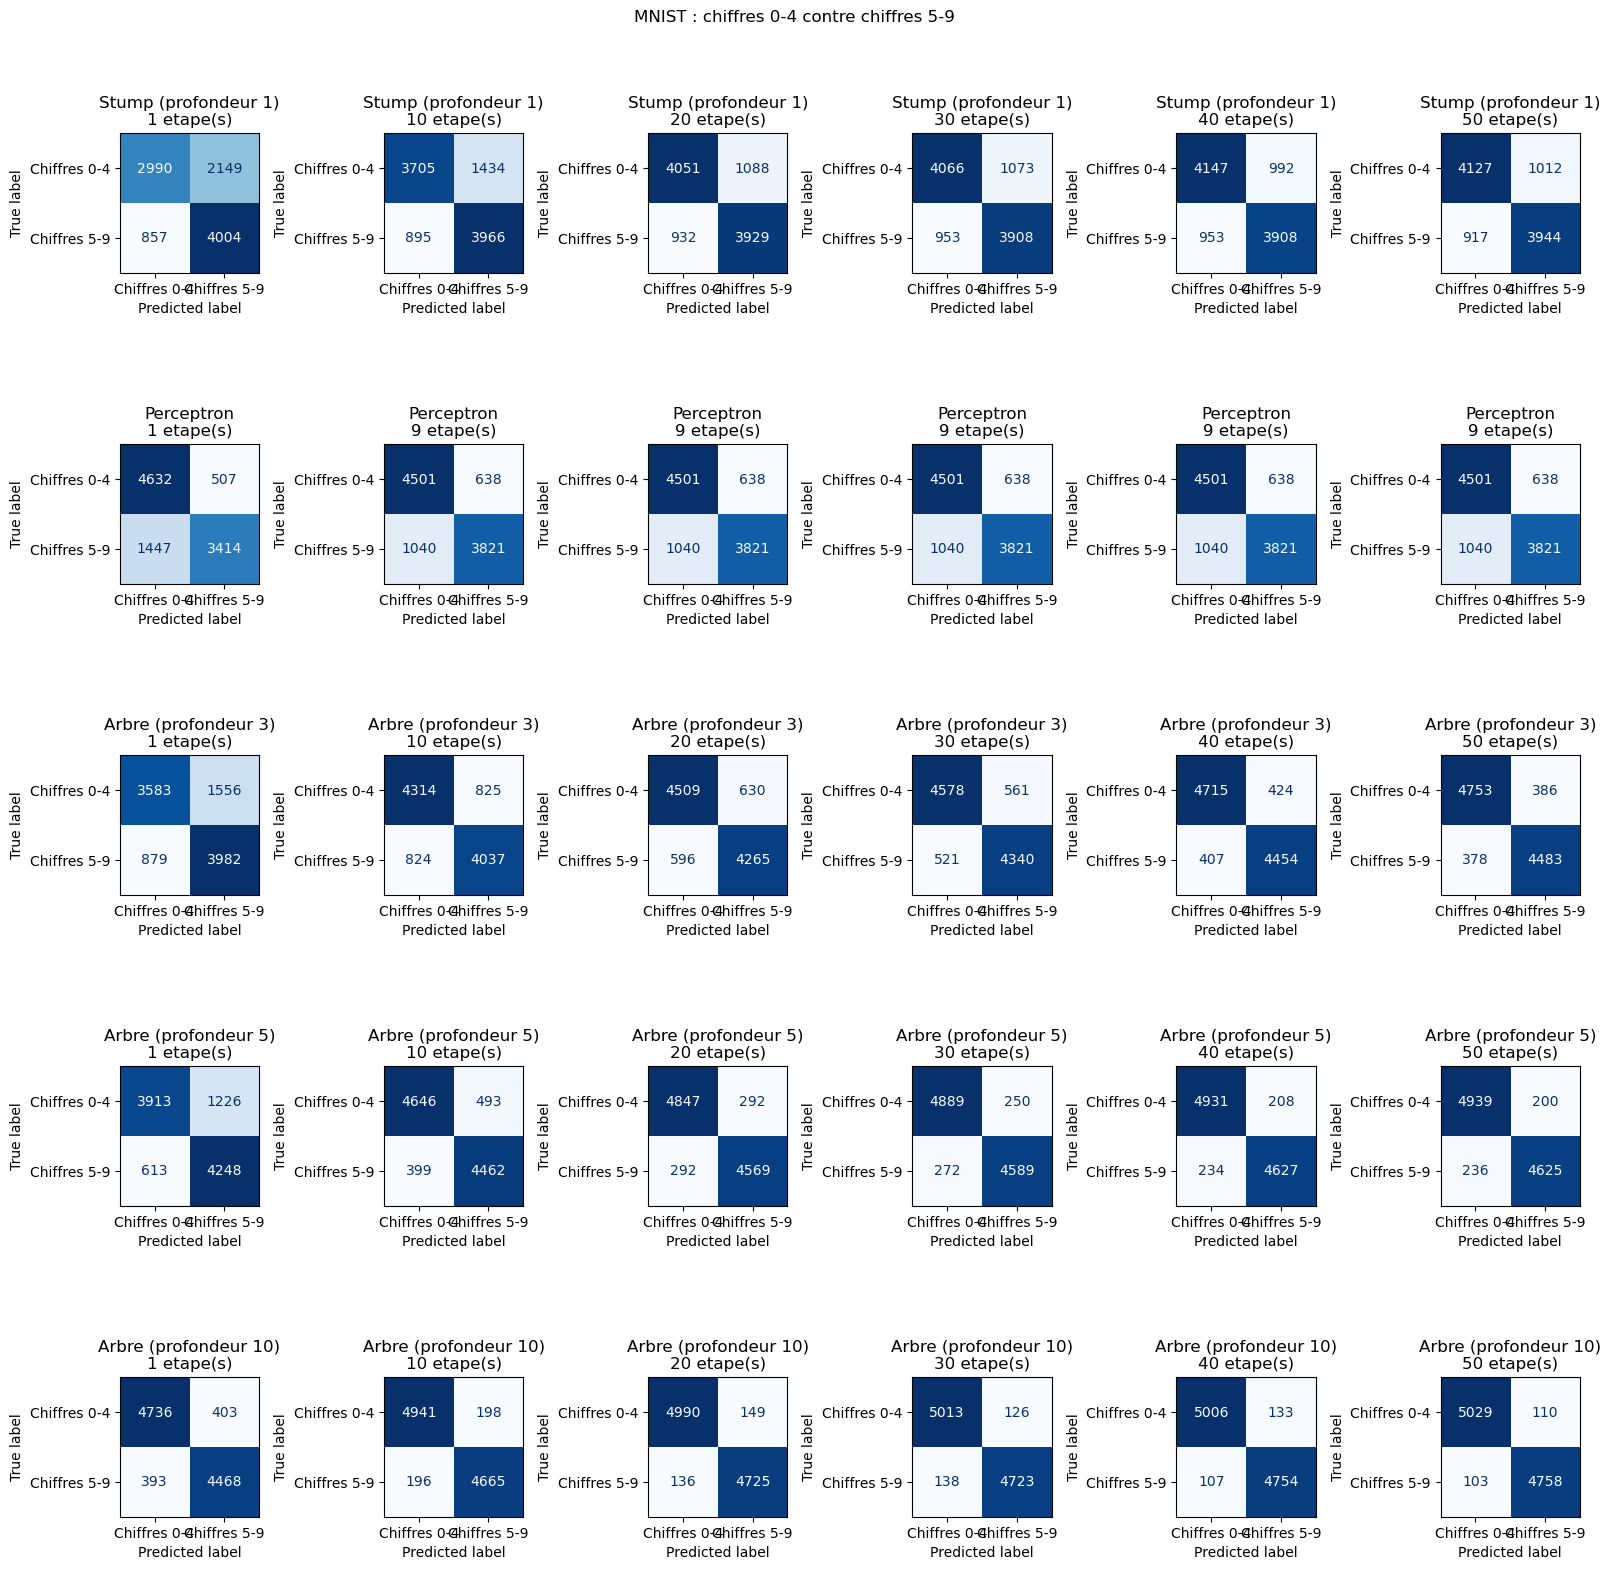

In [17]:
nb_lignes = len(configurations)
fig, axes = plt.subplots(
    nb_lignes, len(ETAPES_A_EVALUER),
    figsize=(16, 3.2 * nb_lignes),
    squeeze=False,
)

for i, (nom, matrices_modele) in enumerate(matrices.items()):
    for j, n_demande in enumerate(ETAPES_A_EVALUER):
        n = min(n_demande, max(matrices_modele))
        cm = matrices_modele[n]
        ConfusionMatrixDisplay(cm, display_labels=noms_classes).plot(
            ax=axes[i, j], cmap='Blues', colorbar=False, values_format='d'
        )
        axes[i, j].set_title(f'{nom}\n{n} etape(s)')

fig.suptitle('MNIST : chiffres 0-4 contre chiffres 5-9', y=1.002)
fig.tight_layout()
plt.show()

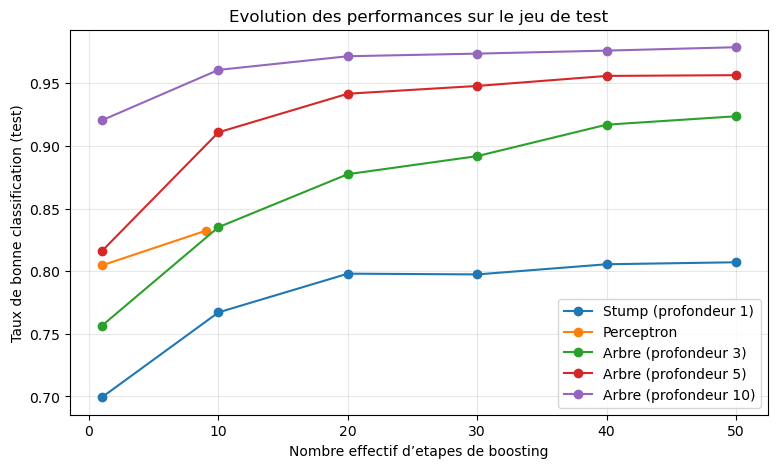

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
for nom, matrices_modele in matrices.items():
    scores = []
    etapes = []
    for n in sorted(matrices_modele):
        cm = matrices_modele[n]
        scores.append(np.trace(cm) / cm.sum())
        etapes.append(n)
    ax.plot(etapes, scores, marker='o', label=nom)

ax.set_xlabel('Nombre effectif d’etapes de boosting')
ax.set_ylabel('Taux de bonne classification (test)')
ax.set_title('Evolution des performances sur le jeu de test')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Bilan

Le tableau ci-dessous classe les configurations selon leur accuracy et leur balanced accuracy. La matrice de confusion permet de verifier si les erreurs concernent davantage l'un des deux groupes. Pour conclure, comparer les meilleurs resultats a faible et grand nombre d'etapes, ainsi que les erreurs des stumps, du perceptron et des arbres plus profonds. Les scores observes a l'execution du notebook servent de base aux conclusions (ils ne sont pas fixes a l'avance).

In [19]:
classement = table_resultats.sort_values(
    ['Balanced accuracy', 'Accuracy'], ascending=False
).reset_index(drop=True)
display(classement[['Classifieur faible', 'Etapes', 'Accuracy', 'Balanced accuracy']])

meilleur = classement.iloc[0]
print(
    f"Meilleure configuration : {meilleur['Classifieur faible']} a "
    f"{int(meilleur['Etapes'])} etape(s), balanced accuracy = "
    f"{meilleur['Balanced accuracy']:.3f}."
)

,Classifieur faible,Etapes,Accuracy,Balanced accuracy
0,Arbre (profondeur 10),50,0.9787,0.978703
1,Arbre (profondeur 10),40,0.9760,0.976054
2,Arbre (profondeur 10),30,0.9736,0.973546
3,Arbre (profondeur 10),20,0.9715,0.971514
4,Arbre (profondeur 10),10,0.9606,0.960575
5,Arbre (profondeur 5),50,0.9564,0.956266
6,Arbre (profondeur 5),40,0.9558,0.955693
7,Arbre (profondeur 5),30,0.9478,0.947698
8,Arbre (profondeur 5),20,0.9416,0.941555
9,Arbre (profondeur 3),50,0.9236,0.923563


Meilleure configuration : Arbre (profondeur 10) a 50 etape(s), balanced accuracy = 0.979.
